# TCMP-300 在线数据增强效果

使用指定的 `001.Veronica persica Poir` 训练图片，展示无增强版的输入，以及增强版的光度、几何和组合效果。这里**只处理和显示图片，不构建或训练模型**。

## 1. 设置与输入

需要 `torch`、`torchvision`、`Pillow` 和 `IPython`。组合示例直接调用 `train_resnet50_ZQ.py` 的增强流水线；图中显示的是张量归一化之前的图像。固定随机种子以便重复生成相同示例。

In [10]:
from pathlib import Path
import sys
import torch
from PIL import Image, ImageDraw, ImageFont, ImageOps
from IPython.display import display
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

project_root = Path.cwd()
if not (project_root / "train_resnet50_ZQ.py").is_file():
    project_root = Path(r"D:\Study\AI全栈开发\TCMP-300")
assert (project_root / "train_resnet50_ZQ.py").is_file(), "找不到 TCMP-300 项目目录"
sys.path.insert(0, str(project_root))
from train_resnet50 import make_eval_transform
from train_resnet50_ZQ import make_augmentation_transform

image_path = project_root / "data" / "author_tcmp_300" / "images" / "tcmp-300" / "train" / "001.Veronica persica Poir" / "3c90b3392c2dbf64d15d4b3f20c89bf6.jpg"
assert image_path.is_file(), f"找不到示例图片：{image_path}"
source_image = Image.open(image_path).convert("RGB")
torch.manual_seed(2026)
font_path = Path(r"C:\Windows\Fonts\msyh.ttc")
label_font = ImageFont.truetype(str(font_path), 22) if font_path.is_file() else ImageFont.load_default()
title_font = ImageFont.truetype(str(font_path), 27) if font_path.is_file() else ImageFont.load_default()

def show_row(samples, title, save_path=None):
    tile = 280
    gap = 16
    top = 72
    label_height = 38
    width = gap + len(samples) * (tile + gap)
    height = top + label_height + tile + gap
    canvas = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(canvas)
    draw.text((width // 2, 17), title, font=title_font, anchor="mt", fill="#161616")
    for index, (label, image) in enumerate(samples):
        x = gap + index * (tile + gap)
        draw.text((x + tile // 2, top), label, font=label_font, anchor="mt", fill="#222222")
        image = ImageOps.contain(image.convert("RGB"), (tile, tile), method=Image.Resampling.LANCZOS)
        image_x = x + (tile - image.width) // 2
        image_y = top + label_height + (tile - image.height) // 2
        canvas.paste(image, (image_x, image_y))
        draw.rectangle((x, top + label_height, x + tile - 1, top + label_height + tile - 1), outline="#dddddd", width=1)
    if save_path is not None:
        canvas.save(save_path)
    display(canvas)

## 2. 原图与基础版输入

基础版对训练和验证图片都使用 `Resize(256) → CenterCrop(224) → ToTensor → Normalize`，没有随机变化。下图显示归一化之前的画面。

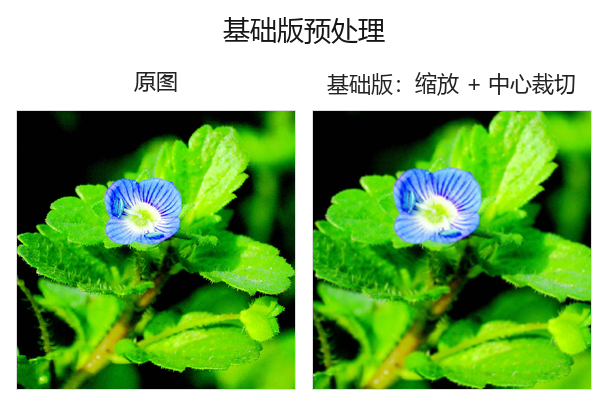

In [11]:
base_image = transforms.Compose(make_eval_transform().transforms[:2])(source_image)
show_row([("原图", source_image), ("基础版：缩放 + 中心裁切", base_image)], "基础版预处理")

## 3. 随机光度变化

增强版的 `ColorJitter` 每次读取图片时在以下范围内采样：亮度和对比度 `0.7–1.3`、饱和度 `0.8–1.2`、色相 `−0.05–0.05`。下面逐项展示允许范围内的固定示例，便于比较。

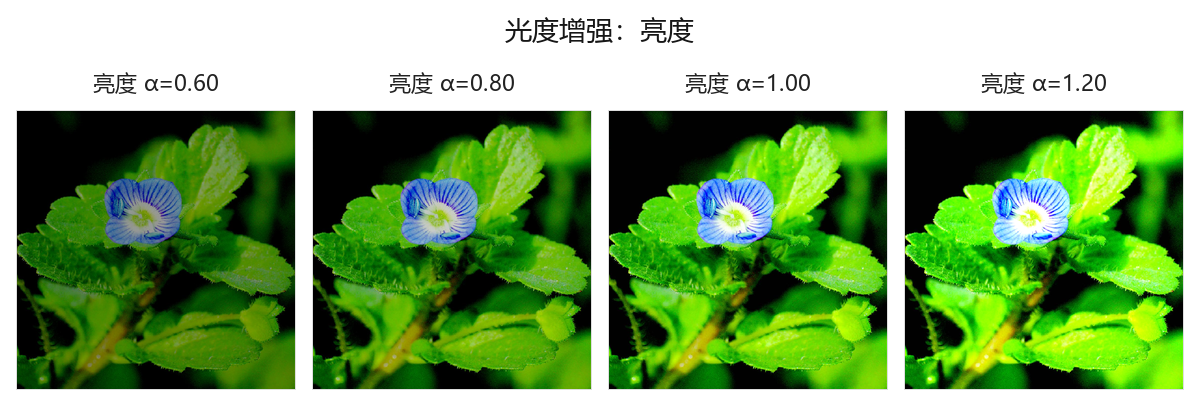

In [15]:
brightness = [0.6, 0.8, 1.0, 1.2]
show_row([(f"亮度 α={factor:.2f}", TF.adjust_brightness(source_image, factor)) for factor in brightness], "光度增强：亮度")

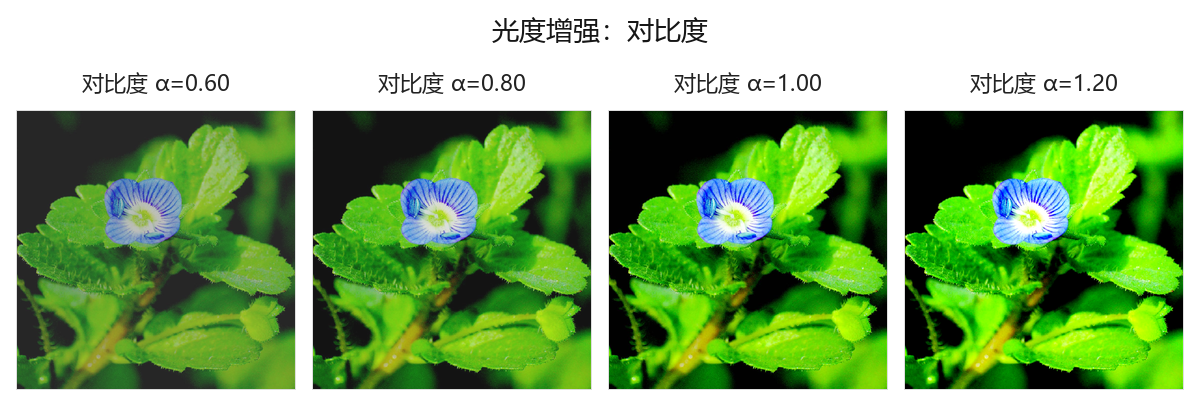

In [16]:
contrast = [0.6, 0.8, 1.0, 1.2]
show_row([(f"对比度 α={factor:.2f}", TF.adjust_contrast(source_image, factor)) for factor in contrast], "光度增强：对比度")

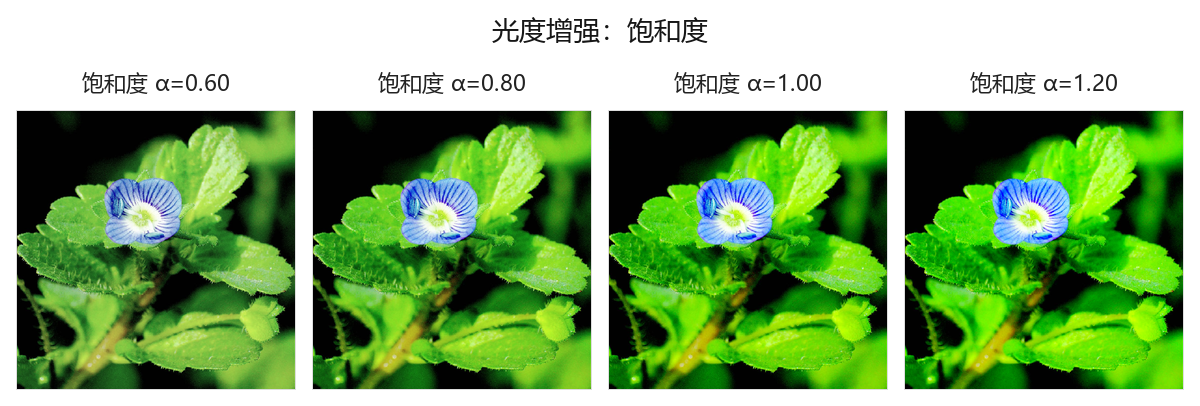

In [17]:
saturation = [0.6, 0.8, 1.0, 1.2]
show_row([(f"饱和度 α={factor:.2f}", TF.adjust_saturation(source_image, factor)) for factor in saturation], "光度增强：饱和度")

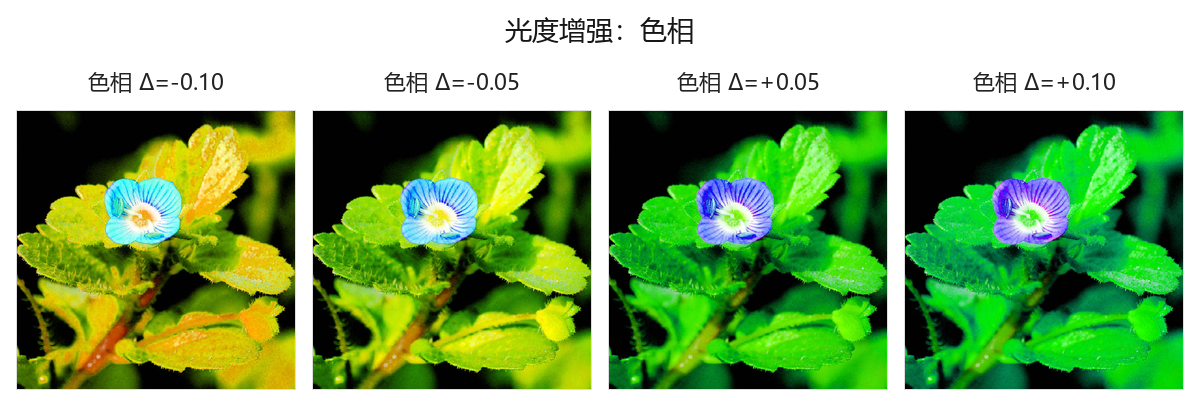

In [18]:
hue = [-0.1, -0.05, 0.05, 0.1]
show_row([(f"色相 Δ={value:+.2f}", TF.adjust_hue(source_image, value)) for value in hue], "光度增强：色相")

## 4. 随机几何变化

增强版使用 `RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.9, 1.1))`、水平和垂直翻转（各 `p=0.5`），以及 `±15°` 随机旋转。下图单独展示每类操作。

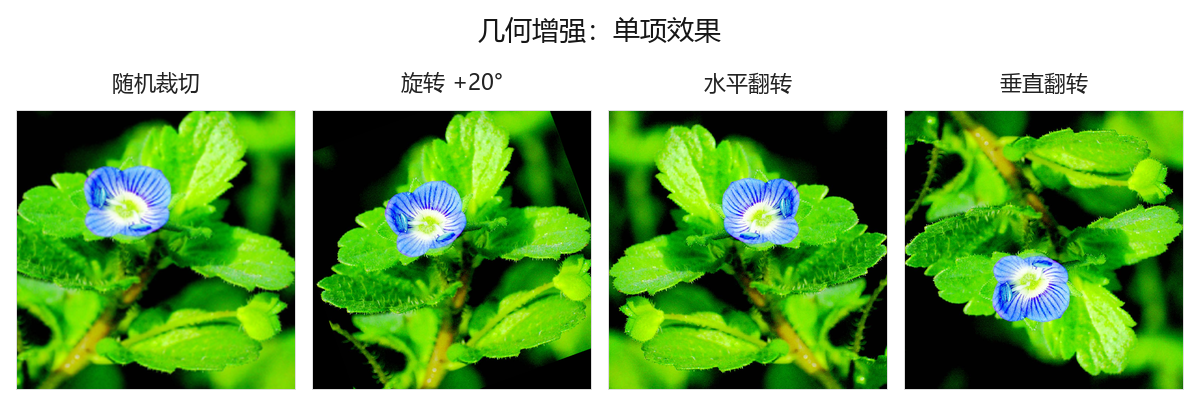

In [19]:
random_crop = transforms.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=InterpolationMode.BILINEAR)
show_row([
    ("随机裁切", random_crop(source_image)),
    ("旋转 +20°", TF.rotate(source_image, 20, interpolation=InterpolationMode.BILINEAR)),
    ("水平翻转", TF.hflip(source_image)),
    ("垂直翻转", TF.vflip(source_image)),
], "几何增强：单项效果")

## 5. 完整在线增强的四次采样

下图四张均由增强版训练脚本的同一流水线生成，每次读取都会重新随机采样。运行此单元还会将图片保存为 `augmentation_preview_ZQ.png`。

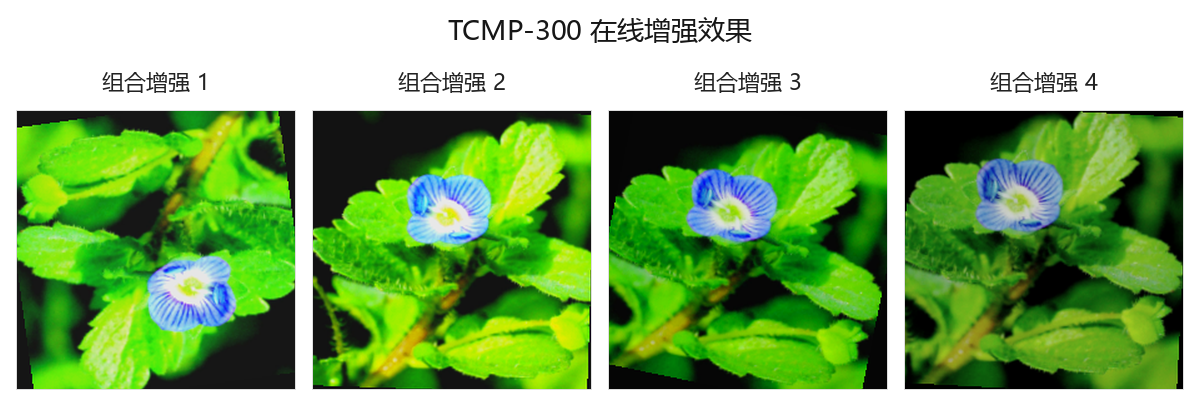

In [20]:
torch.manual_seed(2026)
online_augmentation = make_augmentation_transform()
samples = [(f"组合增强 {index}", online_augmentation(source_image)) for index in range(1, 5)]
preview_path = project_root / "augmentation_preview_ZQ.png"
show_row(samples, "TCMP-300 在线增强效果", save_path=preview_path)

## 6. 说明

以上只展示图像变换，没有加载 ResNet-50 权重或运行训练。两版训练脚本共享模型与优化流程；基础版无随机增强，增强版只对训练集做随机增强，验证集仍使用固定的基础版预处理。